# Проект-Времето в Лондон






# Въведение
Представеният набор от данни обхваща изчерпателен запис на метеорологични наблюдения, предоставяйки ценна информация за метеорологичните условия за определен период.Времевият обхват на набора от данни, пространственото покритие и богатството от записани параметри допринасят за неговото значение в различни области, включително метеорология, климатология и наука за околната среда.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


 Входни променливи:

 1.date - записана дата на измерване - (int)

2.cloud_cover - измерване на облачността в окта - (float)

3.sunshine - измерване на слънчевото греене в часове (hrs) - (float)

4.global_radiation - измерване на радиацията във ватове на квадратен метър (W/m2) - (float)

5.max_temp - записана максимална температура в градуси по Целзий (°C) - (float)

6.mean_temp - средна температура в градуси по Целзий (°C) - (float)

7.min_temp - минимална температура, записана в градуси по Целзий (°C) - (float)

8.precipitation - измерване на валежите в милиметри (mm) - (float)

9.pressure - измерване на налягането в паскали (Pa) - (float)

10.snow_depth - измерване на дълбочината на снега в сантиметри (cm) - (float)




In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Прочитаме файла london_weather.csv чрез pandas и го задаваме на data frame, наречена weather_dataset.

In [ ]:
file_path ="/content/drive/MyDrive/london_weather.csv"

In [ ]:
weather_dataset = pd.read_csv(file_path)

Mожем да проверим първите пет реда от dataseta

In [ ]:
weather_dataset.head()

,date,cloud_cover,sunshine,global_radiation,max_temp,mean_temp,min_temp,precipitation,pressure,snow_depth
0,19790101,2.0,7.0,52.0,2.3,-4.1,-7.5,0.4,101900.0,9.0
1,19790102,6.0,1.7,27.0,1.6,-2.6,-7.5,0.0,102530.0,8.0
2,19790103,5.0,0.0,13.0,1.3,-2.8,-7.2,0.0,102050.0,4.0
3,19790104,8.0,0.0,13.0,-0.3,-2.6,-6.5,0.0,100840.0,2.0
4,19790105,6.0,2.0,29.0,5.6,-0.8,-1.4,0.0,102250.0,1.0


In [ ]:
weather_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15341 entries, 0 to 15340
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              15341 non-null  int64  
 1   cloud_cover       15322 non-null  float64
 2   sunshine          15341 non-null  float64
 3   global_radiation  15322 non-null  float64
 4   max_temp          15335 non-null  float64
 5   mean_temp         15305 non-null  float64
 6   min_temp          15339 non-null  float64
 7   precipitation     15335 non-null  float64
 8   pressure          15337 non-null  float64
 9   snow_depth        13900 non-null  float64
dtypes: float64(9), int64(1)
memory usage: 1.2 MB


## Проверяваме дали има липстващи данни,ако има ги попълваме

In [ ]:
weather_dataset.isnull().sum()

date                   0
cloud_cover           19
sunshine               0
global_radiation      19
max_temp               6
mean_temp             36
min_temp               2
precipitation          6
pressure               4
snow_depth          1441
dtype: int64

Може да видите, че повечето колони имат липсващи данни - колоната snow_depth имат най-голям брой липсващи стойности.

In [ ]:
missing_val_coll =["cloud_cover","global_radiation","max_temp","mean_temp","min_temp","precipitation","pressure","snow_depth"]

In [ ]:
for col in missing_val_coll:
  mean = weather_dataset[col].mean()
  weather_dataset[col].fillna(mean, inplace=True)

In [ ]:
weather_dataset.isnull().sum()

date                0
cloud_cover         0
sunshine            0
global_radiation    0
max_temp            0
mean_temp           0
min_temp            0
precipitation       0
pressure            0
snow_depth          0
dtype: int64

Сега може да видите,че вече нямаме липстващи стойности

### Можем да видим малко статистическа информация за цифровите колони, включително средните стойности, стандартното отклонение, минималните и максималните стойности, чрез метода describe()

In [ ]:
weather_dataset.describe()

,date,cloud_cover,sunshine,global_radiation,max_temp,mean_temp,min_temp,precipitation,pressure,snow_depth
count,1.534100e+04,15341.000000,15341.000000,15341.000000,15341.000000,15341.000000,15341.000000,15341.000000,15341.000000,15341.000000
mean,1.999567e+07,5.268242,4.350238,118.756951,15.388777,11.475511,7.559867,1.668634,101536.605594,0.037986
std,1.212176e+05,2.068790,4.028339,88.843200,6.553472,5.722981,5.326409,3.737809,1049.585735,0.519373
min,1.979010e+07,0.000000,0.000000,8.000000,-6.200000,-7.600000,-11.800000,0.000000,95960.000000,0.000000
25%,1.989070e+07,4.000000,0.500000,41.000000,10.500000,7.100000,3.500000,0.000000,100920.000000,0.000000
50%,2.000010e+07,6.000000,3.500000,95.000000,15.000000,11.400000,7.800000,0.000000,101620.000000,0.000000
75%,2.010070e+07,7.000000,7.200000,186.000000,20.300000,16.000000,11.800000,1.600000,102240.000000,0.000000
max,2.020123e+07,9.000000,16.000000,402.000000,37.900000,29.000000,22.300000,61.800000,104820.000000,22.000000


In [ ]:
# # Извличане на колоните Ден, Месец и Година от колоната date и след това изтриване на колоната date
weather_dataset['date'] = pd.to_datetime(weather_dataset['date'],format="%Y%m%d")
weather_dataset['day'] = weather_dataset['date'].dt.day
weather_dataset['month'] = weather_dataset['date'].dt.month
weather_dataset['year'] = weather_dataset['date'].dt.year
weather_dataset = weather_dataset.drop('date', axis=1)
weather_dataset.head()

,cloud_cover,sunshine,global_radiation,max_temp,mean_temp,min_temp,precipitation,pressure,snow_depth,day,month,year
0,2.0,7.0,52.0,2.3,-4.1,-7.5,0.4,101900.0,9.0,1,1,1979
1,6.0,1.7,27.0,1.6,-2.6,-7.5,0.0,102530.0,8.0,2,1,1979
2,5.0,0.0,13.0,1.3,-2.8,-7.2,0.0,102050.0,4.0,3,1,1979
3,8.0,0.0,13.0,-0.3,-2.6,-6.5,0.0,100840.0,2.0,4,1,1979
4,6.0,2.0,29.0,5.6,-0.8,-1.4,0.0,102250.0,1.0,5,1,1979


Заместваме цифрите с имената на месеците

In [ ]:
data = {'month': [1,2,3,4,5,6,7,8,9,10,11,12],\
        'month_name': ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]}
month_name = pd.DataFrame(data)
weather_dataset = weather_dataset.merge(month_name,on = 'month',how = 'left')

In [ ]:
weather_dataset.head()

,cloud_cover,sunshine,global_radiation,max_temp,mean_temp,min_temp,precipitation,pressure,snow_depth,day,month,year,month_name
0,2.0,7.0,52.0,2.3,-4.1,-7.5,0.4,101900.0,9.0,1,1,1979,January
1,6.0,1.7,27.0,1.6,-2.6,-7.5,0.0,102530.0,8.0,2,1,1979,January
2,5.0,0.0,13.0,1.3,-2.8,-7.2,0.0,102050.0,4.0,3,1,1979,January
3,8.0,0.0,13.0,-0.3,-2.6,-6.5,0.0,100840.0,2.0,4,1,1979,January
4,6.0,2.0,29.0,5.6,-0.8,-1.4,0.0,102250.0,1.0,5,1,1979,January


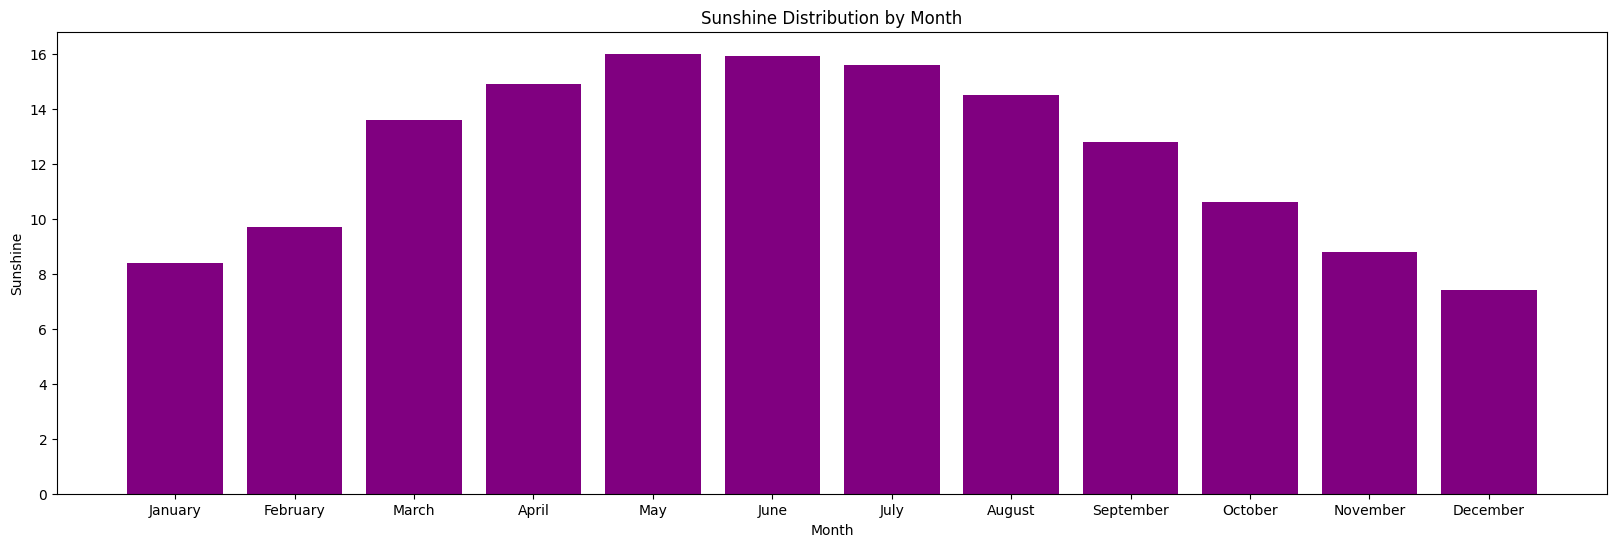

In [ ]:
plt.figure(figsize=(20, 6))
plt.bar(weather_dataset['month_name'],weather_dataset['sunshine'],color='purple')
plt.title('Sunshine Distribution by Month')
plt.xlabel('Month')
plt.ylabel('Sunshine')
plt.show()

Тази стълбовидна диаграма илюстрира разпределението на слънчевите часове през месеците в Лондон.Диаграмата предоставя ценна представа за сезонните вариации в продължителността на слънчевата светлина, като ни помага да разберем годишните метеорологични модели в Лондон.

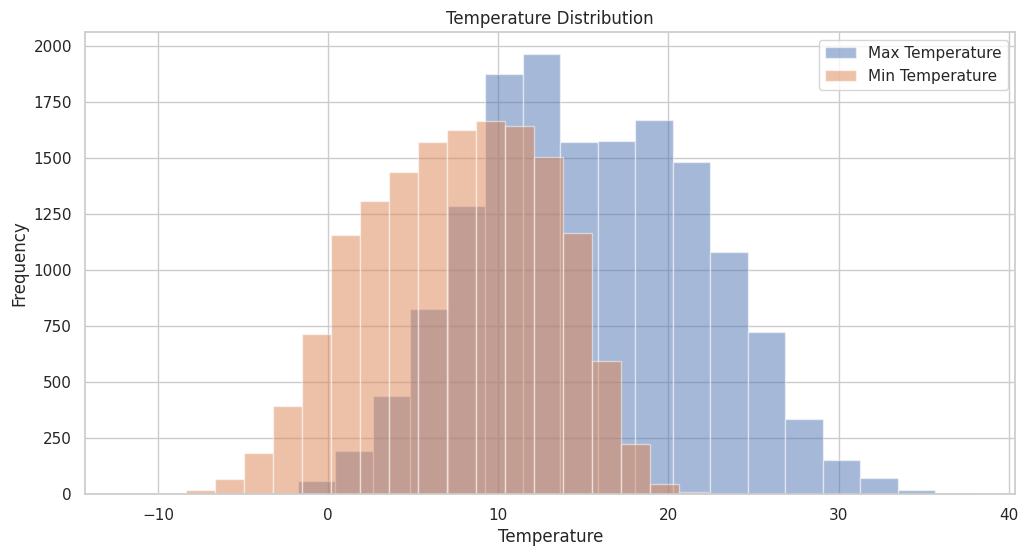

In [ ]:
plt.figure(figsize=(12, 6))
plt.hist(weather_dataset['max_temp'], bins=20, alpha=0.5, label='Max Temperature')
plt.hist(weather_dataset['min_temp'], bins=20, alpha=0.5, label='Min Temperature')
plt.xlabel('Temperature')
plt.ylabel('Frequency')
plt.title('Temperature Distribution')
plt.legend()
plt.show()

Диаграмата на температурното разпределение показва,че 10°C-15°C се среща най-често в датасета.

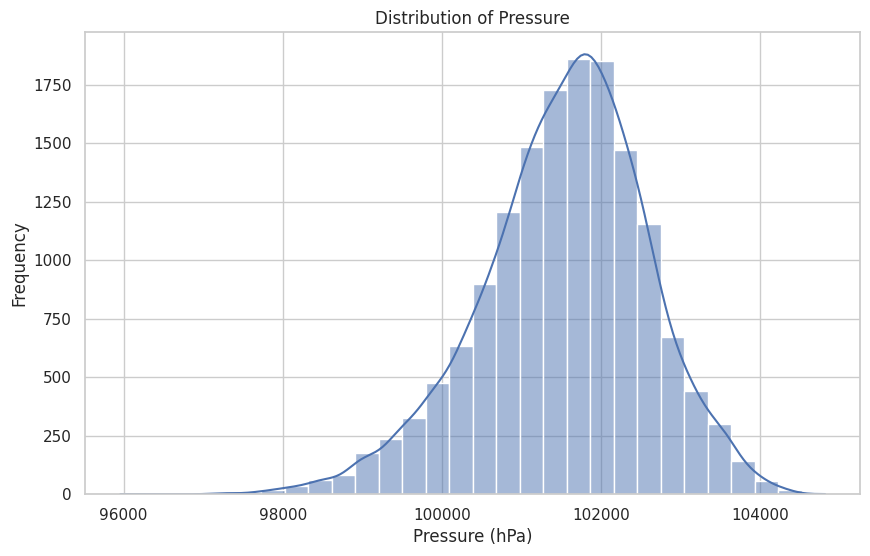

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(weather_dataset['pressure'], bins=30, kde=True)
plt.title('Distribution of Pressure')
plt.xlabel('Pressure (hPa)')
plt.ylabel('Frequency')
plt.show()

Представената диаграма илюстрира разпределението на нивата на атмосферното налягане в наблюдавания dataset. Атмосферното налягане е основен метеорологичен параметър, който оказва влияние върху метеорологичните модели и условия.В графиката на разпределението на налягането забелязваме ясна тенденция. През повечето време налягането се движи около 101 000 и 102 000 хектопаскала (hPa).

---



Линейната диаграма илюстрира вариациите на радиацията с течение на времето, предоставяйки представа за моделите и тенденциите, наблюдавани в dataset.Тази визуализация помага за разбирането на времевата динамика на глобалната радиация, което е от решаващо значение за оценка на наличността на енергия и условията на околната среда.

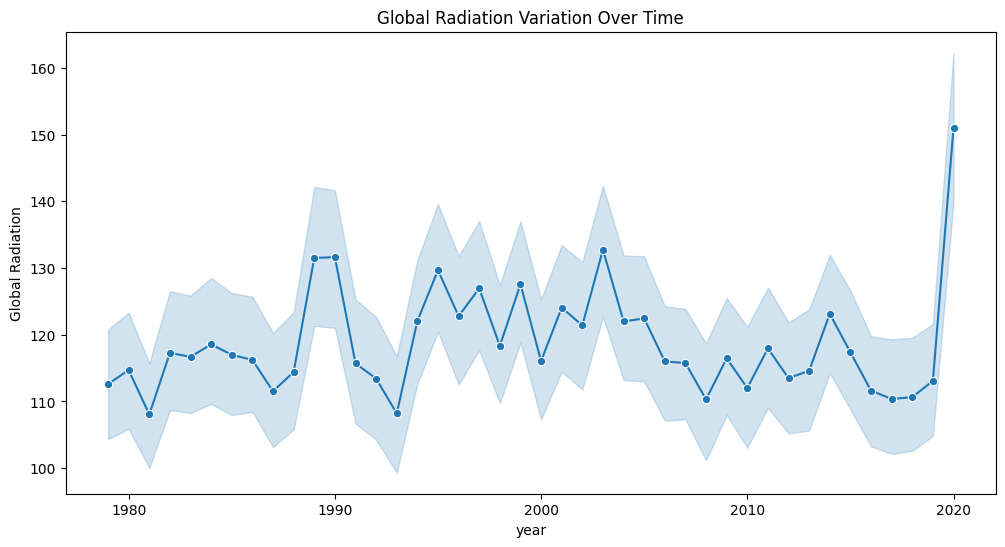

In [ ]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='year', y='global_radiation', data=weather_dataset, marker='o')
plt.title('Global Radiation Variation Over Time')
plt.xlabel('year')
plt.ylabel('Global Radiation')
plt.show()

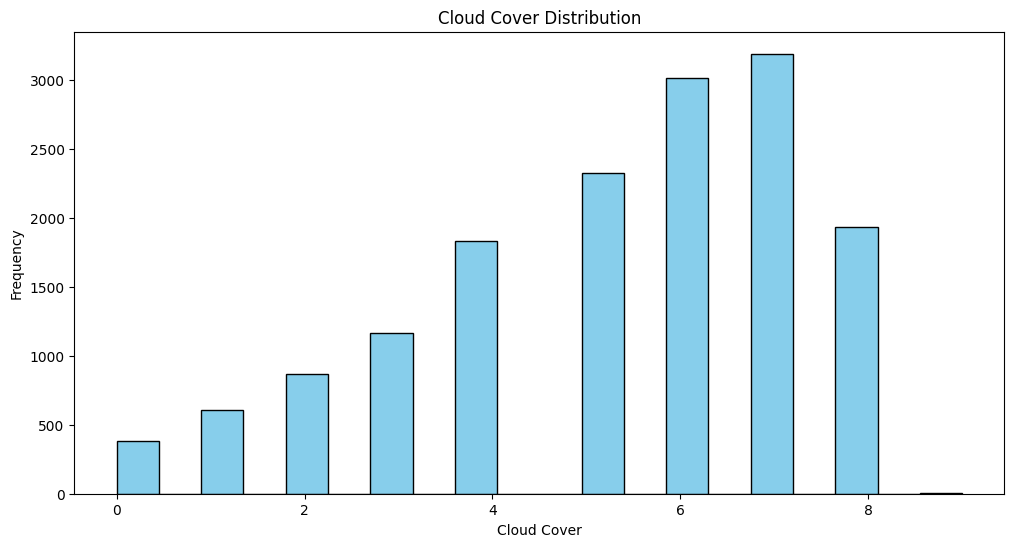

In [ ]:
plt.figure(figsize=(12, 6))
plt.hist(weather_dataset['cloud_cover'], bins=20, color='skyblue', edgecolor='black')
plt.xlabel('Cloud Cover')
plt.ylabel('Frequency')
plt.title('Cloud Cover Distribution')
plt.show()

От хистограмата виждаме, че най-често облачното покритие е на 6,7 окта.Тази информация може да бъде ценна за разбирането на типичните условия на облачно покритие в датасета и може да предостави представа за времето в Лондон.

In [ ]:
weather_dataset.corr()

<ipython-input-16-9b2ee83f4b77>:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  weather_dataset.corr()


,cloud_cover,sunshine,global_radiation,max_temp,mean_temp,min_temp,precipitation,pressure,snow_depth,day,month,year
cloud_cover,1.000000,-0.737884,-0.484820,-0.211913,-0.110273,0.048763,0.235058,-0.241651,-0.001185,0.011674,-0.020247,-0.106864
sunshine,-0.737884,1.000000,0.849974,0.472112,0.396130,0.219076,-0.231602,0.226924,-0.032330,-0.006969,-0.033842,0.009163
global_radiation,-0.484820,0.849974,1.000000,0.689729,0.633862,0.477701,-0.162590,0.150027,-0.058045,-0.003041,-0.092200,0.008390
max_temp,-0.211913,0.472112,0.689729,1.000000,0.911442,0.810284,-0.071798,0.100419,-0.123654,0.008912,0.183816,0.086271
mean_temp,-0.110273,0.396130,0.633862,0.911442,1.000000,0.954532,-0.010455,0.004758,-0.147051,0.009544,0.226806,0.093647
min_temp,0.048763,0.219076,0.477701,0.810284,0.954532,1.000000,0.037229,-0.074259,-0.150163,0.011499,0.251753,0.094587
precipitation,0.235058,-0.231602,-0.162590,-0.071798,-0.010455,0.037229,1.000000,-0.349362,-0.001284,0.006900,0.034344,0.008020
pressure,-0.241651,0.226924,0.150027,0.100419,0.004758,-0.074259,-0.349362,1.000000,-0.020531,0.007941,-0.039766,-0.013309
snow_depth,-0.001185,-0.032330,-0.058045,-0.123654,-0.147051,-0.150163,-0.001284,-0.020531,1.000000,-0.030345,-0.055355,-0.040916
day,0.011674,-0.006969,-0.003041,0.008912,0.009544,0.011499,0.006900,0.007941,-0.030345,1.000000,0.010457,0.000045


In [ ]:
def plot_corr(dataframe,size=10):

    corr = dataframe.corr()

    fig, ax = plt.subplots(figsize=(size, size))
    ax.matshow(corr)
    plt.xticks(range(len(corr.columns)), corr.columns,rotation = 90)
    plt.yticks(range(len(corr.columns)), corr.columns)

<ipython-input-47-41809a231c74>:3: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr = dataframe.corr()


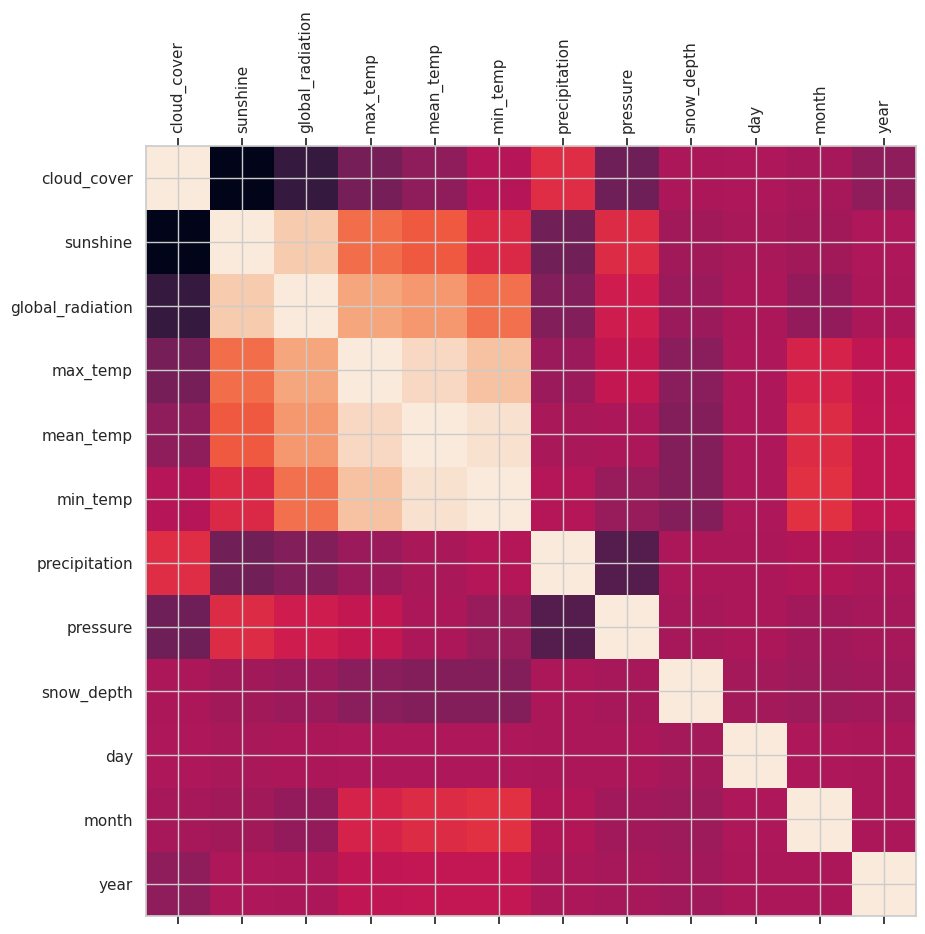

In [ ]:
plot_corr(weather_dataset)

In [ ]:
corr = weather_dataset.corr()
corr.style.background_gradient(cmap='coolwarm')

<ipython-input-49-477407017c3e>:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr = weather_dataset.corr()


,cloud_cover,sunshine,global_radiation,max_temp,mean_temp,min_temp,precipitation,pressure,snow_depth,day,month,year
cloud_cover,1.000000,-0.738291,-0.485973,-0.212224,-0.110556,0.048838,0.235269,-0.241955,-0.001256,0.011680,-0.020270,-0.107003
sunshine,-0.738291,1.000000,0.852632,0.472182,0.396535,0.219082,-0.231636,0.226943,-0.034222,-0.006969,-0.033842,0.009163
global_radiation,-0.485973,0.852632,1.000000,0.690946,0.635432,0.478119,-0.162668,0.150078,-0.061781,-0.003043,-0.092202,0.008395
max_temp,-0.212224,0.472182,0.690946,1.000000,0.912200,0.810514,-0.071799,0.100455,-0.130594,0.008913,0.183841,0.086319
mean_temp,-0.110556,0.396535,0.635432,0.912200,1.000000,0.955593,-0.010462,0.004764,-0.154945,0.009557,0.227076,0.093743
min_temp,0.048838,0.219082,0.478119,0.810514,0.955593,1.000000,0.037233,-0.074274,-0.157882,0.011500,0.251754,0.094605
precipitation,0.235269,-0.231636,-0.162668,-0.071799,-0.010462,0.037233,1.000000,-0.349456,-0.001352,0.006902,0.034347,0.008024
pressure,-0.241955,0.226943,0.150078,0.100455,0.004764,-0.074274,-0.349456,1.000000,-0.021229,0.007943,-0.039774,-0.013311
snow_depth,-0.001256,-0.034222,-0.061781,-0.130594,-0.154945,-0.157882,-0.001352,-0.021229,1.000000,-0.031872,-0.056709,-0.043567
day,0.011680,-0.006969,-0.003043,0.008913,0.009557,0.011500,0.006902,0.007943,-0.031872,1.000000,0.010457,0.000045


Може да видим,че висока корелация има между mean_temp и max_temp,mean_temp и min_temp и също между global_radiation и sunshine. Коефициентът на корелация показва силна линейна връзка, разкриваща, че периодите с увеличена продължителност на слънчевото греене са постоянно придружени от по-високи нива на глобална радиация.

#Заключение

### Изследвахме датасета за времето в Лондон.Проверихме дали е необходимо да подредим или изчистим.След това направихме анализ и визуализирахме данните чрез диаграми.Също представихме различни корелации и направихме изводи.